# Logistic Regression Classification

This notebook demonstrates how to build, train, and evaluate a Logistic Regression model using `scikit-learn`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc

## 1. Generate Synthetic Data
We will create a binary classification dataset for demonstration purposes.

In [2]:
# Generate synthetic binary classification dataset
X, y = make_classification(n_samples=1000, n_features=4, n_informative=2, n_redundant=2, random_state=42)

# Convert to DataFrame for visualization
df = pd.DataFrame(X, columns=[f'Feature_{i+1}' for i in range(4)])
df['Target'] = y
display(df.head())

,Feature_1,Feature_2,Feature_3,Feature_4,Target
0,-1.607711,-0.029398,1.569953,-0.527984,1
1,0.290131,0.317681,-0.996519,0.477009,0
2,-1.225096,0.895911,-0.900324,0.719861,1
3,2.046861,-1.680595,1.923718,-1.427244,1
4,1.828884,-0.289261,-1.049151,0.206271,0


## 2. Train-Test Split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (800, 4)
Testing set shape: (200, 4)


## 3. Train the Logistic Regression Model

In [4]:
model = LogisticRegression()
model.fit(X_train, y_train)
print("Model training complete.")

Model training complete.


## 4. Evaluate the Model

In [5]:
# Predict on test data
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

# Print metrics
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8850

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.91      0.89       101
           1       0.90      0.86      0.88        99

    accuracy                           0.89       200
   macro avg       0.89      0.88      0.88       200
weighted avg       0.89      0.89      0.88       200



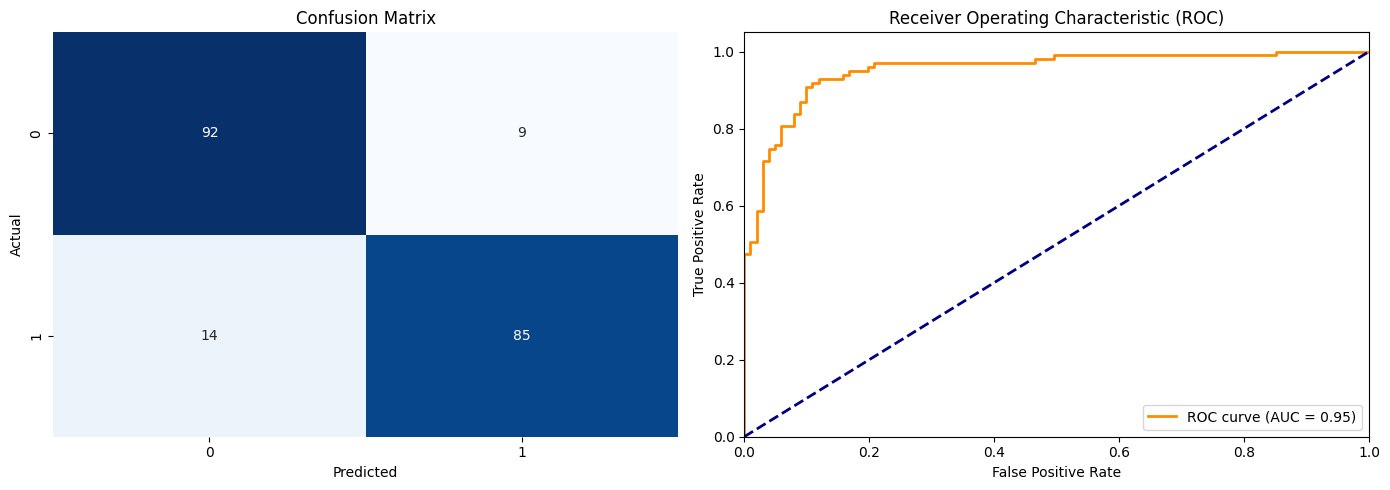

In [6]:
# Plot Confusion Matrix and ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()